# Ex 5 - Modele Markov Ascunse (HMM)

## 1. Formalizarea Modelului

### Starile ascunse și Obs
* **Stările ascunse (Dificultatea testului):** $Q = \{q_1: \text{Dificil}, q_2: \text{Mediu}, q_3: \text{Ușor}\}$
* **Observațiile (Notabilitatea obținută):** $O = \{\text{FB}, \text{B}, \text{S}, \text{NS}\}$

### Parametrii Modelului HMM: $\lambda = (\pi, A, B)$
1. **Vectorul prob. initiale $\pi$** (Curs 4, Slide 7):
   Probabilitatea primului test este aceeași pentru toate cele 3 stări:
   $$\pi = \begin{pmatrix} \pi_1 & \pi_2 & \pi_3 \end{pmatrix} = \begin{pmatrix} \frac{1}{3} & \frac{1}{3} & \frac{1}{3} \end{pmatrix}$$

2. **Matricea de tranzitie $A = (a_{ij})_{3 \times 3}$** unde $a_{ij} = P(S_{t+1} = q_j \mid S_t = q_i)$
   * $q_1 (\text{Dificil}) \rightarrow$ tranziție doar spre $q_2$ sau $q_3$ cu probabilitatea $0.5$.
   * $q_2 (\text{Mediu}) \rightarrow$ tranziție spre $q_1$ cu $0.5$, spre $q_2$ cu $0.25$, spre $q_3$ cu $0.25$.
   * $q_3 (\text{Ușor}) \rightarrow$ tranziție spre $q_1$ cu $0.5$, spre $q_2$ cu $0.25$, spre $q_3$ cu $0.25$.

   $$A = \begin{pmatrix}
   0 & 0.5 & 0.5 \\
   0.5 & 0.25 & 0.25 \\
   0.5 & 0.25 & 0.25
   \end{pmatrix}$$

3. **Matricea emisiilor $B = (b_j(o_k))_{3 \times 4}$** :
   Coloanele corespund observatiilor $(\text{FB}, \text{B}, \text{S}, \text{NS})$:
   $$B = \begin{pmatrix}
   0.10 & 0.20 & 0.40 & 0.30 \\
   0.15 & 0.25 & 0.50 & 0.10 \\
   0.20 & 0.30 & 0.40 & 0.10
   \end{pmatrix}$$

---

## 2. Relatiile de Calcul ale Algoritmului Viterbi

Pentru secventa observata $O = (\text{FB}, \text{FB}, \text{S}, \text{B}, \text{B}, \text{S}, \text{B}, \text{NS}, \text{B}, \text{B}, \text{S})$ de lungime $T = 11$:

* **Pasul 1 (Initializare):**
  $$\delta_1(j) = \pi_j \cdot b_j(o_1), \quad \forall j \in \{1, 2, 3\}$$

* **Pasul 2 (Recursie):**
  $$\delta_t(j) = b_j(o_t) \cdot \max_{1 \le i \le 3} \{\delta_{t-1}(i) \cdot a_{ij}\}$$
  $$\psi_t(j) = \arg\max_{1 \le i \le 3} \{\delta_{t-1}(i) \cdot a_{ij}\}$$

* **Pasul 3 (Terminare):**
  $$P(S^*, O) = \max_{1 \le j \le 3} \{\delta_T(j)\}, \quad q_T^* = \arg\max_{1 \le j \le 3} \{\delta_T(j)\}$$

* **Pasul 4 (BKT):**
  $$q_t^* = \psi_{t+1}(q_{t+1}^*), \quad t = T-1, T-2, \dots, 1$$

##a)

In [5]:
!pip install hmmlearn

import numpy as np
from hmmlearn import hmm

# a) def modelului markov ascuns
model = hmm.CategoricalHMM(n_components=3, init_params="")

# setarea parametrilor pi, A, B
model.startprob_ = np.array([1/3, 1/3, 1/3])

model.transmat_ = np.array([
    [0.0,  0.5,  0.5],   # dificil
    [0.5,  0.25, 0.25],  # mediu
    [0.5,  0.25, 0.25]   # usor
])

model.emissionprob_ = np.array([
    [0.1,  0.2,  0.4, 0.3],   # dificil: FB, B, S, NS
    [0.15, 0.25, 0.5, 0.1],   # mediu:   FB, B, S, NS
    [0.2,  0.3,  0.4, 0.1]    # usor:    FB, B, S, NS
])

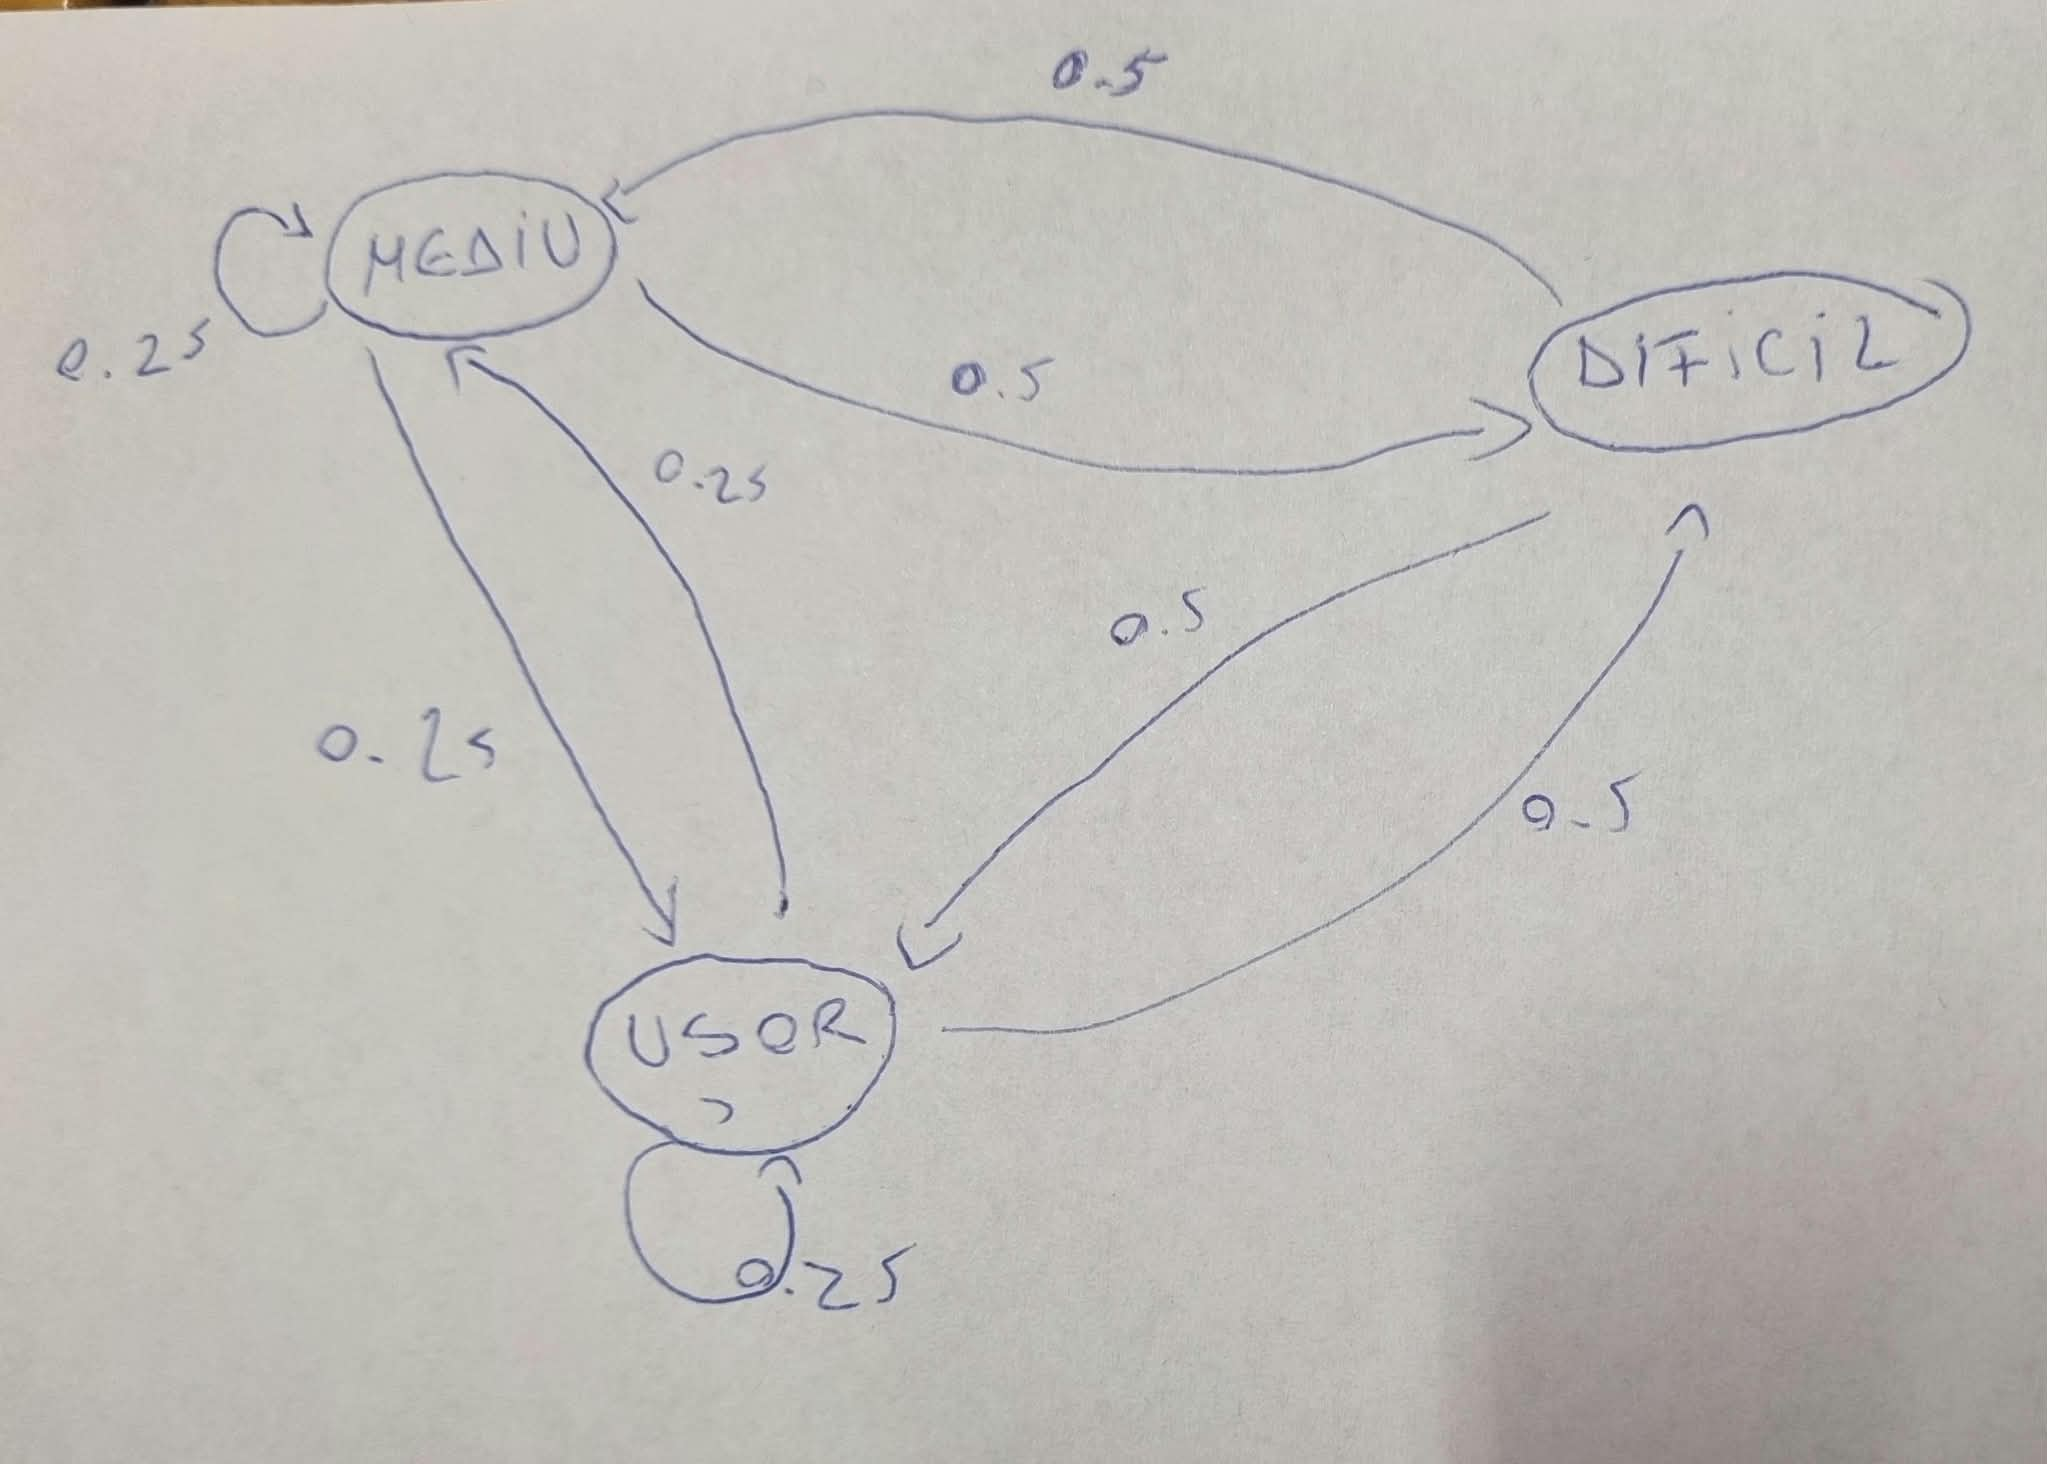

## b) Secvența de note observata

In [2]:
obs_map = {'FB': 0, 'B': 1, 'S': 2, 'NS': 3}
obs_labels = ['FB', 'FB', 'S', 'B', 'B', 'S', 'B', 'NS', 'B', 'B', 'S']
O = np.array([[obs_map[x]] for x in obs_labels])

# metoda 1: cu hmmlearn
log_prob, state_sequence = model.decode(O, algorithm="viterbi")
states_names = {0: 'Dificil', 1: 'Mediu', 2: 'Ușor'}

predicted_sequence = [states_names[s] for s in state_sequence]
prob_comuna = np.exp(log_prob)

print("--- REZULTAT DECODARE (hmmlearn) ---")
print("secventa cea mai probabila de dificultati:")
print(" -> ".join(predicted_sequence))
print(f"prob secv : P(S*, O) = {prob_comuna:.12e}\n")


# metoda 2: implementarea pas cu pas a alg Viterbi
T = len(O)
delta = np.zeros((T, 3))
psi = np.zeros((T, 3), dtype=int)

# pasul 1: init
delta[0, :] = model.startprob_ * model.emissionprob_[:, O[0][0]]

# pasul 2: recursie
for t in range(1, T):
    for j in range(3):
        prev_vals = delta[t-1, :] * model.transmat_[:, j]
        psi[t, j] = np.argmax(prev_vals)
        delta[t, j] = model.emissionprob_[j, O[t][0]] * np.max(prev_vals)

# pasul 3 & 4: BKT
best_last_state = np.argmax(delta[T-1, :])
viterbi_prob = delta[T-1, best_last_state]

path = [best_last_state]
for t in range(T-1, 0, -1):
    best_last_state = psi[t, best_last_state]
    path.insert(0, best_last_state)

manual_sequence = [states_names[s] for s in path]

print("--- REZULTAT CALCUL MANUAL VITERBI (Curs 4) ---")
print("secventa cea mai probabila de dificultati:")
print(" -> ".join(manual_sequence))
print(f"prob P(S*, O) = {viterbi_prob:.12e}")

--- REZULTAT DECODARE (hmmlearn) ---
secventa cea mai probabila de dificultati:
Ușor -> Dificil -> Mediu -> Dificil -> Ușor -> Dificil -> Ușor -> Dificil -> Ușor -> Dificil -> Mediu
prob secv : P(S*, O) = 2.109375000000e-10

--- REZULTAT CALCUL MANUAL VITERBI (Curs 4) ---
secventa cea mai probabila de dificultati:
Ușor -> Dificil -> Mediu -> Dificil -> Ușor -> Dificil -> Ușor -> Dificil -> Ușor -> Dificil -> Mediu
prob P(S*, O) = 2.109375000000e-10
